# Day 3: Gene filtering and shared cross-validation folds

**Problem:** ~39,000 genes, 1,031 patients, only 139 deaths. A model can easily find "predictive" genes by chance.

**Plan**
1. Restrict to the Day 2 cohort (same patients as the clinical baseline)
2. *Unsupervised* gene filter (never looks at survival, so it cannot leak): protein-coding, expressed, most variable
3. Create **one fixed set of CV folds** that every model will share
4. Fast univariate Cox screening, done **inside training folds only**
5. Demonstrate leakage: select genes on all data vs inside folds, on real and on shuffled labels

**Needs:** `data/processed/X_expression.pkl`, `data/processed/clinical.pkl`, `data/Homo_sapiens.gene_info.gz` (all from Days 1-2) and `src/survival_utils.py`

In [1]:
import sys, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from lifelines import CoxPHFitter

sys.path.append("../src")
from survival_utils import cox_score_screen, make_folds, save_folds, load_folds

DATA = Path("../data")
RES = Path("../results")
FIGS = RES / "figures"
FIGS.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})

N_VARIABLE = 5000    # genes kept after the unsupervised filter
K = 50               # genes selected per training fold

## 1. Load data and restrict to the Day 2 cohort

In [2]:
X_all = pd.read_pickle(DATA / "processed" / "X_expression.pkl")
clin = pd.read_pickle(DATA / "processed" / "clinical.pkl")      # 1,031 patients with age + stage

X = X_all.loc[clin.index]
del X_all
t = clin["time"].values                  # years
e = clin["event"].values.astype(int)

print("X:", X.shape, "| patients:", len(clin), "| deaths:", e.sum())
assert X.index.equals(clin.index)

X: (1031, 39452) | patients: 1031 | deaths: 139


## 2. Unsupervised gene filter
These steps use only expression, never survival, so they cannot leak outcome information:
1. protein-coding genes only (NCBI gene table)
2. expressed: TPM >= 1 (log2(TPM+1) >= 1) in at least 20% of patients
3. keep the 5,000 most variable genes

In [3]:
gi = pd.read_csv(DATA / "Homo_sapiens.gene_info.gz", sep="\t", usecols=["Symbol", "type_of_gene"])
coding = set(gi.loc[gi["type_of_gene"] == "protein-coding", "Symbol"])

steps = {"all genes": X.shape[1]}
X = X.loc[:, X.columns.isin(coding)]
steps["protein-coding"] = X.shape[1]

X = X.loc[:, (X >= 1).mean(axis=0) >= 0.20]
steps["expressed (TPM>=1 in >=20% of patients)"] = X.shape[1]

X = X[X.var(axis=0).nlargest(N_VARIABLE).index]
steps[f"top {N_VARIABLE} most variable"] = X.shape[1]

pd.Series(steps, name="genes remaining")

all genes                                  39452
protein-coding                             19179
expressed (TPM>=1 in >=20% of patients)    14455
top 5000 most variable                      5000
Name: genes remaining, dtype: int64

## 3. One fixed set of CV folds for every model
5-fold, repeated 10 times (50 folds), stratified by stage + event. These are the **same folds as Day 2**, so the baseline can be compared fold by fold. They are saved to `results/folds.json`.

In [4]:
strat = (clin["stage"].astype(str) + "_" + clin["event"].astype(int).astype(str)).values
folds = make_folds(strat, n_splits=5, n_repeats=10, seed=42)
save_folds(RES / "folds.json", clin.index.tolist(), folds)

# every patient should be in exactly one test fold per repeat
counts = np.bincount(np.concatenate([te for _, te in folds]), minlength=len(clin))
print("folds:", len(folds), "| times each patient is tested:", counts.min(), "-", counts.max())
print("train size:", len(folds[0][0]), "| test size:", len(folds[0][1]))

folds: 50 | times each patient is tested: 10 - 10
train size: 824 | test size: 207


**Sanity check:** re-run the clinical baseline on these saved folds. It should reproduce the Day 2 number, and I also store the per-fold scores for later paired comparisons.

In [5]:
base = pd.DataFrame({"time": t, "event": e, "age_per10y": clin["AGE"].values / 10}, index=clin.index)
dummies = pd.get_dummies(clin["stage"], prefix="stage").astype(float).drop(columns="stage_I")
base = pd.concat([base, dummies], axis=1)

base_scores = []
for tr, te in folds:
    m = CoxPHFitter(penalizer=0.01).fit(base.iloc[tr], "time", "event")
    base_scores.append(m.score(base.iloc[te], scoring_method="concordance_index"))
base_scores = np.array(base_scores)

prev = json.load(open(RES / "clinical_baseline.json"))
print(f"Baseline on saved folds: {base_scores.mean():.3f} +/- {base_scores.std():.3f}")
print(f"Day 2 value:             {prev['cindex_cv_mean']:.3f} +/- {prev['cindex_cv_sd']:.3f}")

json.dump({"model": "Cox age + stage (ridge 0.01)", "fold_scores": base_scores.tolist()},
          open(RES / "baseline_fold_scores.json", "w"))

C:\Users\AmirAboulfazl\anaconda3\envs\tcga\Lib\site-packages\lifelines\fitters\coxph_fitter.py:1614: ConvergenceWarning: Newton-Raphson failed to converge sufficiently. Please see the following tips in the lifelines documentation: https://lifelines.readthedocs.io/en/latest/Examples.html#problems-with-convergence-in-the-cox-proportional-hazard-model
  warnings.warn(
C:\Users\AmirAboulfazl\anaconda3\envs\tcga\Lib\site-packages\lifelines\fitters\coxph_fitter.py:1614: ConvergenceWarning: Newton-Raphson failed to converge sufficiently. Please see the following tips in the lifelines documentation: https://lifelines.readthedocs.io/en/latest/Examples.html#problems-with-convergence-in-the-cox-proportional-hazard-model
  warnings.warn(
C:\Users\AmirAboulfazl\anaconda3\envs\tcga\Lib\site-packages\lifelines\fitters\coxph_fitter.py:1614: ConvergenceWarning: Newton-Raphson failed to converge sufficiently. Please see the following tips in the lifelines documentation: https://lifelines.readthedocs.io/

Baseline on saved folds: 0.739 +/- 0.046
Day 2 value:             0.739 +/- 0.046


## 4. Fast univariate Cox screening
`cox_score_screen` tests all genes at once with the Cox score test. Check it against lifelines on a few genes first.

In [6]:
Xv = X.values.astype(np.float64)
z, p = cox_score_screen(Xv, t, e)

rng = np.random.default_rng(0)
pick = np.concatenate([np.argsort(-np.abs(z))[:4], rng.choice(Xv.shape[1], 4, replace=False)])
rows = []
for j in pick:
    d = pd.DataFrame({"x": Xv[:, j], "time": t, "event": e})
    s = CoxPHFitter().fit(d, "time", "event").summary.loc["x"]
    rows.append({"gene": X.columns[j], "fast z (score)": z[j], "lifelines z (Wald)": s["z"]})
check = pd.DataFrame(rows).round(2)
print(check.to_string(index=False))
print("correlation:", round(np.corrcoef(check.iloc[:, 1], check.iloc[:, 2])[0, 1], 3))

  gene  fast z (score)  lifelines z (Wald)
   CEL            5.20                5.22
 L1CAM            4.43                4.36
 KLRB1           -4.02               -3.99
JCHAIN           -3.89               -3.87
 CTXN1           -1.26               -1.26
 SNAI2            0.52                0.52
 FOXD1            2.58                2.56
 ITGB5           -0.04               -0.04
correlation: 1.0


## 5. Gene selection inside each training fold
In every fold, the top 50 genes by |z| are chosen using **training patients only**. Counting how often each gene is chosen shows which genes are stable and which are noise.

screened 50 folds in 18.1s
genes ever selected: 359 of 5000
genes selected in >= 80% of folds: 4
genes selected in >= 50% of folds: 30


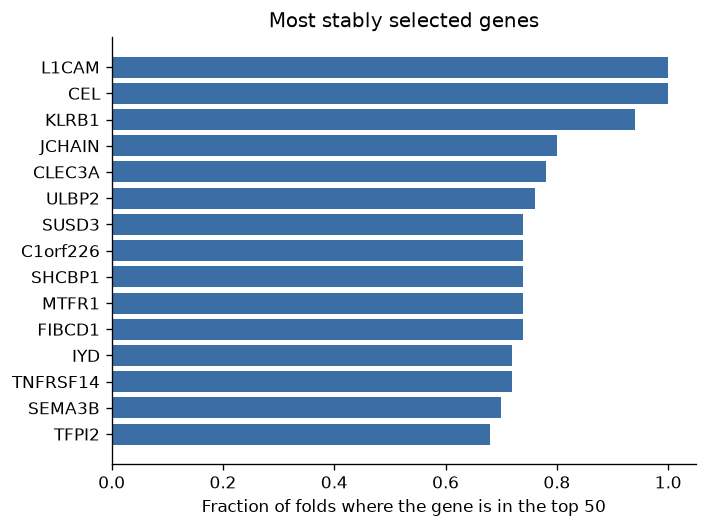

In [7]:
freq = np.zeros(Xv.shape[1])
t0 = time.time()
for tr, te in folds:
    zf, _ = cox_score_screen(Xv[tr], t[tr], e[tr])
    freq[np.argsort(-np.abs(zf))[:K]] += 1
print(f"screened {len(folds)} folds in {time.time() - t0:.1f}s")

freq = pd.Series(freq / len(folds), index=X.columns).sort_values(ascending=False)
print("genes ever selected:", int((freq > 0).sum()), "of", len(freq))
print("genes selected in >= 80% of folds:", int((freq >= 0.8).sum()))
print("genes selected in >= 50% of folds:", int((freq >= 0.5).sum()))

top = freq.head(15)
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.barh(top.index[::-1], top.values[::-1], color="#3b6ea5")
ax.set_xlabel(f"Fraction of folds where the gene is in the top {K}")
ax.set_title("Most stably selected genes")
plt.tight_layout()
plt.savefig(FIGS / "gene_selection_stability.png", dpi=200)
plt.show()

## 6. Leakage demo: select genes on all data vs inside the folds
Same model (ridge Cox on the top 50 genes), same folds. The only difference is *where* genes are selected.

- **Leaky:** genes chosen once using all patients, including the ones later used for testing
- **Correct:** genes chosen again inside every training fold

Then repeat with **shuffled survival labels**. Shuffled data has no real signal, so an honest pipeline must score ~0.5.

In [8]:
def cv_gene_model(Xm, tt, ee, folds, k=K, leaky=False, penalizer=0.1):
    names = [f"g{i}" for i in range(k)]
    top_all = np.argsort(-np.abs(cox_score_screen(Xm, tt, ee)[0]))[:k] if leaky else None
    scores = []
    for tr, te in folds:
        cols = top_all if leaky else np.argsort(-np.abs(cox_score_screen(Xm[tr], tt[tr], ee[tr])[0]))[:k]
        dtr = pd.DataFrame(Xm[np.ix_(tr, cols)], columns=names); dtr["time"] = tt[tr]; dtr["event"] = ee[tr]
        dte = pd.DataFrame(Xm[np.ix_(te, cols)], columns=names); dte["time"] = tt[te]; dte["event"] = ee[te]
        m = CoxPHFitter(penalizer=penalizer).fit(dtr, "time", "event")
        scores.append(m.score(dte, scoring_method="concordance_index"))
    return np.array(scores)

perm = np.random.default_rng(123).permutation(len(t))
t_perm, e_perm = t[perm], e[perm]       # shuffled labels: no real signal

results = {}
for label, (tt, ee) in {"real labels": (t, e), "shuffled labels": (t_perm, e_perm)}.items():
    for leaky in (True, False):
        name = f"{label} | {'leaky' if leaky else 'correct'}"
        results[name] = cv_gene_model(Xv, tt, ee, folds, leaky=leaky)
        print(f"{name:32s} C-index = {results[name].mean():.3f} +/- {results[name].std():.3f}")

real labels | leaky              C-index = 0.732 +/- 0.053
real labels | correct            C-index = 0.609 +/- 0.059
shuffled labels | leaky          C-index = 0.663 +/- 0.061
shuffled labels | correct        C-index = 0.521 +/- 0.067


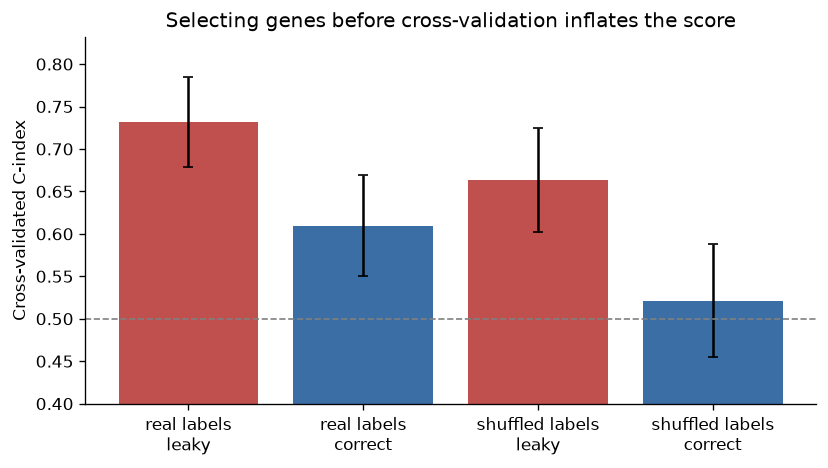

In [9]:
names = list(results)
means = [results[n].mean() for n in names]
sds = [results[n].std() for n in names]
colors = ["#c0504d" if "leaky" in n else "#3b6ea5" for n in names]

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(range(len(names)), means, yerr=sds, color=colors, capsize=3)
ax.axhline(0.5, color="gray", ls="--", lw=1)
ax.set_xticks(range(len(names)))
ax.set_xticklabels([n.replace(" | ", "\n") for n in names])
ax.set_ylabel("Cross-validated C-index")
ax.set_ylim(0.4, max(means) + 0.1)
ax.set_title("Selecting genes before cross-validation inflates the score")
plt.tight_layout()
plt.savefig(FIGS / "leakage_demo.png", dpi=200)
plt.show()

json.dump({n: {"mean": float(results[n].mean()), "sd": float(results[n].std())} for n in names},
          open(RES / "leakage_demo.json", "w"), indent=2)

**How to read it:** on shuffled labels the *correct* pipeline stays at or slightly below 0.5 (as it should, since there is nothing to find), while the *leaky* one scores far above 0.5. This is the inflation that makes many published expression-signature results look better than they are.

## 7. Save the filtered matrix for Day 4

In [10]:
X.to_pickle(DATA / "processed" / "X_filtered.pkl")
pd.Series(X.columns, name="gene").to_csv(RES / "filtered_genes.csv", index=False)
print("saved X_filtered:", X.shape)

saved X_filtered: (1031, 5000)


### Summary
- Gene set reduced from ~39,000 to 5,000 with filters that never look at survival.
- One shared, saved set of 50 folds. Every model is compared on the same splits.
- Gene selection must happen *inside* training folds. Day 4 will use `cox_score_screen` in a pipeline.
- Next (Day 4): penalized Cox (Coxnet) and Random Survival Forest on `X_filtered`, evaluated on `folds.json` against the clinical baseline.